<a href="https://colab.research.google.com/github/Imabung/Exploring-Kiva-Loans-with-Pandas/blob/main/Exploring_Kiva_Loans_with_Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Exploring Kiva Loans with Pandas

## Introduction

This project explores the Kiva crowdfunding loan dataset using Python and the Pandas library.

The dataset contains information about loans provided through Kiva, including loan amounts, funding amounts, borrower characteristics, business activities, countries and repayment periods.

The purpose of this analysis is to investigate six questions about lending patterns, borrower characteristics and crowdfunding behaviour. The analysis uses data filtering, sorting, grouping, aggregation and the creation of new variables.

The dataset was obtained from Kaggle:

[Data Science for Good: Kiva Crowdfunding](https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding)


In [ ]:
import pandas as pd

df = pd.read_csv('/content/kiva_loans.csv')

df[['loan_amount', 'funded_amount', 'lender_count']].head()


,loan_amount,funded_amount,lender_count
0,300.0,300.0,12
1,575.0,575.0,14
2,150.0,150.0,6
3,200.0,200.0,8
4,400.0,400.0,16


## Question 1: Do smaller loans have a higher chance of being fully funded, and how does lender participation vary with loan size?

In [ ]:
df[['loan_amount', 'funded_amount', 'lender_count']].describe()


,loan_amount,funded_amount,lender_count
count,671205.000000,671205.000000,671205.000000
mean,842.397107,785.995061,20.590922
std,1198.660073,1130.398941,28.459551
min,25.000000,0.000000,0.000000
25%,275.000000,250.000000,7.000000
50%,500.000000,450.000000,13.000000
75%,1000.000000,900.000000,24.000000
max,100000.000000,100000.000000,2986.000000


In [ ]:
df['loan_size_group'] = df['loan_amount'].apply(
    lambda x:"Small" if x <= 500 else "Medium" if x <= 1000 else "Large"
)

In [ ]:
df[['loan_amount', 'loan_size_group']].head(10)

,loan_amount,loan_size_group
0,300.0,Small
1,575.0,Medium
2,150.0,Small
3,200.0,Small
4,400.0,Small
5,250.0,Small
6,200.0,Small
7,400.0,Small
8,475.0,Small
9,625.0,Medium


In [ ]:
df['loan_size_group'].value_counts()

,count
loan_size_group,
Small,359569
Medium,161943
Large,149693


In [ ]:
df['fully_funded'] = df['funded_amount'] >= df['loan_amount']

df['fully_funded'].value_counts()

,count
fully_funded,
True,622877
False,48328


In [ ]:
loan_analysis = df.groupby('loan_size_group').agg(
    total_loans=('id', 'count'),
    funding_rate=('fully_funded', 'mean'),
    average_lenders=('lender_count', 'mean')
)

loan_analysis['funding_rate'] = loan_analysis['funding_rate'] * 100

loan_analysis

,total_loans,funding_rate,average_lenders
loan_size_group,,,
Large,149693,84.866360,49.812062
Medium,161943,89.857542,20.226796
Small,359569,97.427754,8.589798


In [ ]:
loan_analysis.sort_values(
    by='funding_rate',
    ascending=False
)

,total_loans,funding_rate,average_lenders
loan_size_group,,,
Small,359569,97.427754,8.589798
Medium,161943,89.857542,20.226796
Large,149693,84.866360,49.812062



### Interpretation

Small loans had the highest full-funding rate at 97.43%, compared with 89.86% for medium loans and 84.87% for large loans. However, large loans attracted more lenders on average (49.81), compared with 8.59 for small loans. This shows that attracting more lenders does not necessarily mean a loan has a higher chance of being fully funded.

## Question 2: Does the same business activity attract different levels of lender support in different countries?

In [ ]:
activity_country_analysis = df.groupby(
    ['activity', 'country']
).agg(
    total_loans=('id', 'count'),
    average_lenders=('lender_count', 'mean'),
    median_lenders=('lender_count', 'median')
).reset_index()

activity_country_filtered = activity_country_analysis[
    activity_country_analysis['total_loans'] >= 100
]

activity_country_filtered.head(20)

,activity,country,total_loans,average_lenders,median_lenders
2,Agriculture,Albania,176,43.801136,39.0
3,Agriculture,Armenia,600,39.261667,37.0
7,Agriculture,Bolivia,397,46.211587,41.0
9,Agriculture,Burkina Faso,244,37.381148,30.0
11,Agriculture,Cambodia,412,25.990291,23.5
12,Agriculture,Cameroon,363,13.823691,12.0
15,Agriculture,Colombia,1104,18.250906,13.0
16,Agriculture,Costa Rica,366,33.816940,30.0
19,Agriculture,Ecuador,1055,27.599052,23.0
21,Agriculture,El Salvador,4554,16.674791,14.0


In [ ]:
sector_country_analysis = df.groupby(
    ['sector', 'country']
).agg(
    total_loans=('id', 'count'),
    average_lenders=('lender_count', 'mean'),
    median_lenders=('lender_count', 'median')
).reset_index()

sector_country_filtered = sector_country_analysis[
    sector_country_analysis['total_loans'] >= 100
]

sector_country_filtered.head(20)

,sector,country,total_loans,average_lenders,median_lenders
0,Agriculture,Albania,719,45.378303,40.0
1,Agriculture,Armenia,4630,39.189201,35.0
2,Agriculture,Azerbaijan,1148,41.759582,39.0
3,Agriculture,Belize,125,33.472000,21.0
5,Agriculture,Bolivia,1257,46.263325,38.0
7,Agriculture,Burkina Faso,577,33.235702,27.0
9,Agriculture,Cambodia,10559,24.779335,22.0
10,Agriculture,Cameroon,744,12.658602,11.0
13,Agriculture,Colombia,4987,16.858231,13.0
15,Agriculture,Costa Rica,934,39.480728,33.0


In [ ]:
sector_country_filtered['sector'].unique()

array(['Agriculture', 'Arts', 'Clothing', 'Construction', 'Education',
       'Entertainment', 'Food', 'Health', 'Housing', 'Manufacturing',
       'Personal Use', 'Retail', 'Services', 'Transportation',
       'Wholesale'], dtype=object)

In [ ]:
sector_country_filtered.groupby('sector').agg(
    countries=('country', 'nunique'),
    total_loans=('total_loans', 'sum'),
    average_lenders=('average_lenders', 'mean')
)

,countries,total_loans,average_lenders
sector,,,
Agriculture,56,179844,35.220528
Arts,21,11061,35.653110
Clothing,45,31957,29.481195
Construction,20,4967,26.748416
Education,28,30193,37.420275
Entertainment,2,322,26.746157
Food,54,135681,31.853810
Health,14,8114,30.486556
Housing,23,32945,25.525977


In [ ]:
agriculture_comparison = sector_country_filtered[
    sector_country_filtered['sector'] == 'Agriculture'
].sort_values(
    by='average_lenders',
    ascending=False
)

agriculture_comparison.head(15)

,sector,country,total_loans,average_lenders,median_lenders
73,Agriculture,United States,403,132.129032,121.0
63,Agriculture,Suriname,195,85.148718,86.0
72,Agriculture,Ukraine,184,68.201087,64.5
40,Agriculture,Moldova,218,66.105505,64.0
24,Agriculture,Haiti,119,65.563025,27.0
50,Agriculture,Paraguay,468,58.873932,50.0
43,Agriculture,Myanmar (Burma),1586,58.064943,33.0
39,Agriculture,Mexico,841,55.946492,32.0
74,Agriculture,Vietnam,2614,52.941086,48.0
57,Agriculture,Senegal,643,49.048212,40.0


In [ ]:
sector_rankings = sector_country_filtered.sort_values(
    by=['sector', 'average_lenders'],
    ascending=[True, False]
)

sector_rankings.groupby('sector').head(5)

,sector,country,total_loans,average_lenders,median_lenders
73,Agriculture,United States,403,132.129032,121.0
63,Agriculture,Suriname,195,85.148718,86.0
72,Agriculture,Ukraine,184,68.201087,64.5
40,Agriculture,Moldova,218,66.105505,64.0
24,Agriculture,Haiti,119,65.563025,27.0
...,...,...,...,...,...
912,Transportation,Palestine,312,39.682692,37.0
901,Transportation,Lebanon,141,37.361702,37.0
888,Transportation,Georgia,280,36.117857,28.5
918,Transportation,Samoa,200,32.940000,23.0


In [ ]:
activity_rankings = activity_country_filtered.sort_values(
    by=['activity', 'average_lenders'],
    ascending=[True, False]
)

activity_rankings.groupby('activity').head(5)

,activity,country,total_loans,average_lenders,median_lenders
68,Agriculture,United States,398,132.412060,120.5
52,Agriculture,Rwanda,228,74.596491,54.0
69,Agriculture,Vietnam,160,51.818750,46.0
22,Agriculture,Georgia,109,51.082569,44.0
7,Agriculture,Bolivia,397,46.211587,41.0
...,...,...,...,...,...
6166,Weaving,Guatemala,308,49.795455,31.0
6168,Weaving,India,432,21.722222,10.0
6159,Weaving,Cambodia,190,19.973684,17.0
6178,Weaving,Pakistan,133,13.812030,13.0


In [ ]:
activity_country_filtered.groupby('activity').agg(
    highest_average_lenders=('average_lenders', 'max'),
    lowest_average_lenders=('average_lenders', 'min'),
    countries_compared=('country', 'nunique')
).sort_values(
    by='highest_average_lenders',
    ascending=False
)

,highest_average_lenders,lowest_average_lenders,countries_compared
activity,,,
Higher education costs,194.876404,8.604954,21
Agriculture,132.412060,9.956857,29
Clothing Sales,92.074561,8.949169,38
Renewable Energy Products,90.295699,9.967480,2
Farming,89.669291,4.723958,38
...,...,...,...
Recycling,12.952000,12.952000,1
Water Distribution,12.911504,12.175141,2
Fuel/Firewood,11.178571,7.759748,2


In [ ]:
sector_country_filtered.groupby('sector').agg(
    highest_average_lenders=('average_lenders', 'max'),
    lowest_average_lenders=('average_lenders', 'min'),
    countries_compared=('country', 'nunique')
).sort_values(
    by='highest_average_lenders',
    ascending=False
)

,highest_average_lenders,lowest_average_lenders,countries_compared
sector,,,
Education,194.876404,8.598684,28
Agriculture,132.129032,5.516678,56
Food,91.491228,7.697452,54
Retail,83.079812,8.368694,51
Clothing,80.055092,8.248175,45
Arts,71.498258,8.408543,21
Health,69.456929,12.977813,14
Services,65.651731,10.232394,44
Transportation,62.356061,8.145349,20


In [ ]:
activity_summary = activity_country_filtered.groupby('activity').agg(
    highest_support=('average_lenders', 'max'),
    lowest_support=('average_lenders', 'min'),
    countries=('country', 'nunique')
).reset_index()

activity_summary = activity_summary.rename(
    columns={'activity': 'category'}
)

sector_summary = sector_country_filtered.groupby('sector').agg(
    highest_support=('average_lenders', 'max'),
    lowest_support=('average_lenders', 'min'),
    countries=('country', 'nunique')
).reset_index()

sector_summary = sector_summary.rename(
    columns={'sector': 'category'}
)

combined_comparison = pd.concat(
    [activity_summary, sector_summary],
    ignore_index=True
)

combined_comparison.sort_values(
    by='highest_support',
    ascending=False
)

,category,highest_support,lowest_support,countries
51,Higher education costs,194.876404,8.604954,21
108,Education,194.876404,8.598684,28
0,Agriculture,132.412060,9.956857,29
104,Agriculture,132.129032,5.516678,56
21,Clothing Sales,92.074561,8.949169,38
...,...,...,...,...
81,Recycling,12.952000,12.952000,1
101,Water Distribution,12.911504,12.175141,2
45,Fuel/Firewood,11.178571,7.759748,2
39,Flowers,10.851775,10.851775,1


In [ ]:
activity_sector_country = df.groupby(
    ['sector', 'activity', 'country']
).agg(
    total_loans=('id', 'count'),
    average_lenders=('lender_count', 'mean'),
    median_lenders=('lender_count', 'median')
).reset_index()

activity_sector_country = activity_sector_country[
    activity_sector_country['total_loans'] >= 100
]

activity_sector_country

,sector,activity,country,total_loans,average_lenders,median_lenders
0,Agriculture,Agriculture,Albania,176,43.801136,39.0
1,Agriculture,Agriculture,Armenia,600,39.261667,37.0
5,Agriculture,Agriculture,Bolivia,397,46.211587,41.0
7,Agriculture,Agriculture,Burkina Faso,244,37.381148,30.0
9,Agriculture,Agriculture,Cambodia,412,25.990291,23.5
...,...,...,...,...,...,...
6142,Transportation,Transportation,Kenya,325,14.144615,11.0
6156,Transportation,Transportation,Pakistan,466,11.298283,11.0
6160,Transportation,Transportation,Peru,432,17.391204,14.0
6161,Transportation,Transportation,Philippines,1261,9.957177,8.0


In [ ]:
activity_coverage = activity_sector_country.groupby(
    ['sector', 'activity']
).agg(
    countries_compared=('country', 'nunique'),
    total_loans=('total_loans', 'sum'),
    average_lender_support=('average_lenders', 'mean')
).reset_index()

activity_coverage.sort_values(
    by='countries_compared',
    ascending=False
)

,sector,activity,countries_compared,total_loans,average_lender_support
80,Retail,Retail,40,23958,29.464066
5,Agriculture,Farming,38,71995,31.308410
17,Clothing,Clothing Sales,38,21443,29.502769
40,Food,Food Production/Sales,34,27300,28.985081
43,Food,Grocery Store,32,14294,25.790835
...,...,...,...,...,...
91,Services,Mobile Transactions,1,113,24.176991
92,Services,Recycling,1,125,12.952000
98,Services,Waste Management,1,276,20.318841
96,Services,Technology,1,172,41.883721


In [ ]:
farming_comparison = activity_sector_country[
    activity_sector_country['activity'] == 'Farming'
].sort_values(
    by='average_lenders',
    ascending=False
)

farming_comparison

,sector,activity,country,total_loans,average_lenders,median_lenders
362,Agriculture,Farming,Suriname,127,89.669291,91.0
371,Agriculture,Farming,Ukraine,150,68.306667,68.0
340,Agriculture,Farming,Moldova,118,62.898305,56.5
373,Agriculture,Farming,Vietnam,428,58.219626,54.0
343,Agriculture,Farming,Myanmar (Burma),772,52.542746,34.0
348,Agriculture,Farming,Palestine,259,44.729730,43.0
339,Agriculture,Farming,Mexico,113,44.557522,29.0
311,Agriculture,Farming,Bolivia,220,43.754545,39.0
307,Agriculture,Farming,Albania,177,42.734463,37.0
332,Agriculture,Farming,Kosovo,153,41.849673,40.0


In [ ]:
activity_country_comparison = activity_sector_country.groupby(
    ['sector', 'activity']
).agg(
    highest_support=('average_lenders', 'max'),
    lowest_support=('average_lenders', 'min'),
    countries_compared=('country', 'nunique'),
    total_loans=('total_loans', 'sum')
).reset_index()

activity_country_comparison = activity_country_comparison.sort_values(
    by='countries_compared',
    ascending=False
)

activity_country_comparison

,sector,activity,highest_support,lowest_support,countries_compared,total_loans
80,Retail,Retail,83.161850,8.843016,40,23958
5,Agriculture,Farming,89.669291,4.723958,38,71995
17,Clothing,Clothing Sales,92.074561,8.949169,38,21443
40,Food,Food Production/Sales,87.734838,6.324295,34,27300
43,Food,Grocery Store,61.522523,9.500000,32,14294
...,...,...,...,...,...,...
91,Services,Mobile Transactions,24.176991,24.176991,1,113
92,Services,Recycling,12.952000,12.952000,1,125
98,Services,Waste Management,20.318841,20.318841,1,276
96,Services,Technology,41.883721,41.883721,1,172


In [ ]:
activity_country_comparison['support_difference'] = (
    activity_country_comparison['highest_support'] -
    activity_country_comparison['lowest_support']
)

activity_country_comparison.sort_values(
    by='support_difference',
    ascending=False
)

,sector,activity,highest_support,lowest_support,countries_compared,total_loans,support_difference
26,Education,Higher education costs,194.876404,8.604954,21,18904,186.271450
0,Agriculture,Agriculture,132.412060,9.956857,29,25680,122.455204
5,Agriculture,Farming,89.669291,4.723958,38,71995,84.945333
17,Clothing,Clothing Sales,92.074561,8.949169,38,21443,83.125393
40,Food,Food Production/Sales,87.734838,6.324295,34,27300,81.410543
...,...,...,...,...,...,...,...
91,Services,Mobile Transactions,24.176991,24.176991,1,113,0.000000
92,Services,Recycling,12.952000,12.952000,1,125,0.000000
98,Services,Waste Management,20.318841,20.318841,1,276,0.000000
96,Services,Technology,41.883721,41.883721,1,172,0.000000


In [ ]:
food_activity_loans = df[
    df['activity'].str.contains('Food', case=False, na=False)
    & (df['lender_count'] > 0)
]

food_activity_loans[
    ['sector', 'activity', 'country', 'lender_count']
].head(10)

,sector,activity,country,lender_count
9,Food,Food Production/Sales,Pakistan,24
24,Food,Food Stall,Pakistan,7
54,Food,Food Market,Senegal,7
61,Food,Food Market,Liberia,6
68,Food,Food Market,Liberia,6
74,Food,Food Stall,Kenya,9
89,Food,Food Market,Liberia,1
94,Food,Food,Liberia,5
95,Food,Food Market,Liberia,10
99,Food,Food Production/Sales,United States,261


In [ ]:
top_activity_differences = activity_country_comparison.head(5)

selected_activities = top_activity_differences[
    ['sector', 'activity']
]

country_details = activity_sector_country.merge(
    selected_activities,
    on=['sector', 'activity']
)

country_details.sort_values(
    by=['activity', 'average_lenders'],
    ascending=[True, False]
).groupby('activity').agg(
    highest_country=('country', 'first'),
    highest_lenders=('average_lenders', 'first'),
    lowest_country=('country', 'last'),
    lowest_lenders=('average_lenders', 'last')
)

,highest_country,highest_lenders,lowest_country,lowest_lenders
activity,,,,
Clothing Sales,The Democratic Republic of the Congo,92.074561,Philippines,8.949169
Farming,Suriname,89.669291,Malawi,4.723958
Food Production/Sales,United States,87.734838,Togo,6.324295
Grocery Store,Rwanda,61.522523,Togo,9.500000
Retail,Burundi,83.161850,Philippines,8.843016


### Interpretation

Lender support varied considerably across countries, even for the same business activity. For example, Farming received an average of 89.67 lenders per loan in Suriname, compared with only 4.72 in Malawi, while Clothing Sales ranged from 92.07 in the Democratic Republic of the Congo to 8.95 in the Philippines. This suggests that the level of lender participation is associated with both the business activity and the country where the loan is requested.

## Question 3: Do people who borrow larger amounts of money get more time to repay their loans?

In [ ]:
df[['loan_amount', 'term_in_months', 'sector']].head(10)

,loan_amount,term_in_months,sector
0,300.0,12.0,Food
1,575.0,11.0,Transportation
2,150.0,43.0,Transportation
3,200.0,11.0,Arts
4,400.0,14.0,Food
5,250.0,4.0,Services
6,200.0,43.0,Agriculture
7,400.0,14.0,Services
8,475.0,14.0,Manufacturing
9,625.0,11.0,Food


In [ ]:
df[['loan_amount', 'term_in_months']].describe()
df['loan_amount'].corr(df['term_in_months'])
repayment_analysis = df.groupby('loan_size_group').agg(
    total_loans=('id', 'count'),
    average_loan_amount=('loan_amount', 'mean'),
    average_repayment_period=('term_in_months', 'mean'),
    median_repayment_period=('term_in_months', 'median')
)

repayment_analysis
repayment_analysis.sort_values(
    by='average_repayment_period',
    ascending=False
)

,total_loans,average_loan_amount,average_repayment_period,median_repayment_period
loan_size_group,,,,
Large,149693,2276.293481,17.113920,14.0
Medium,161943,742.215008,14.610134,14.0
Small,359569,290.568500,11.941677,11.0


### Interpretation

The results show that borrowers who take larger loans receive longer repayment periods, small loans had an average repayment period of 11.94 months, compared with 14.61 months for medium loans and 17.11 months for large loans. The correlation also indicates a weak positive relationship between loan amount and repayment period. This explains that loan size is related to repayment time, although the relationship is not particularly strong.

## Question 4: Which economic sectors receive the most loans?

In [ ]:
df['sector'].value_counts()

,count
sector,
Agriculture,180302
Food,136657
Retail,124494
Services,45140
Personal Use,36385
Housing,33731
Clothing,32742
Education,31013
Transportation,15518


In [ ]:
sector_loan_counts = df.groupby('sector').agg(
    total_loans=('id', 'count')
)

sector_loan_counts = sector_loan_counts.sort_values(
    by='total_loans',
    ascending=False
)

sector_loan_counts

,total_loans
sector,
Agriculture,180302
Food,136657
Retail,124494
Services,45140
Personal Use,36385
Housing,33731
Clothing,32742
Education,31013
Transportation,15518


In [ ]:
sector_loan_counts['percentage'] = (
    sector_loan_counts['total_loans'] / len(df)
) * 100

sector_loan_counts

,total_loans,percentage
sector,,
Agriculture,180302,26.862434
Food,136657,20.359950
Retail,124494,18.547836
Services,45140,6.725218
Personal Use,36385,5.420848
Housing,33731,5.025439
Clothing,32742,4.878092
Education,31013,4.620496
Transportation,15518,2.311961


<Axes: title={'center': 'Number of Kiva Loans by Economic Sector'}, xlabel='Economic Sector', ylabel='Number of Loans'>

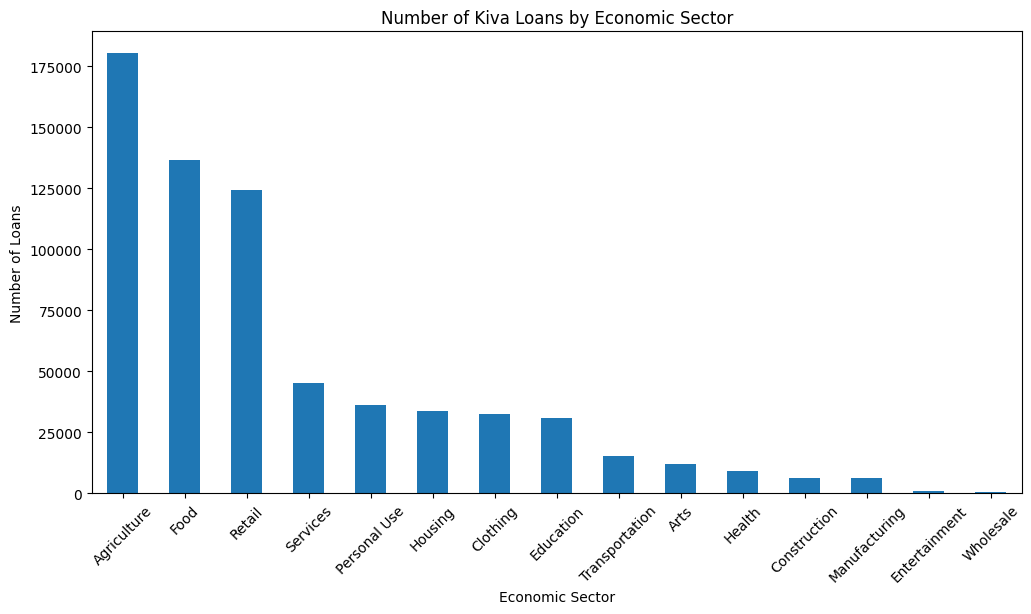

In [ ]:
sector_loan_counts['total_loans'].plot(
    kind='bar',
    figsize=(12, 6),
    title='Number of Kiva Loans by Economic Sector',
    xlabel='Economic Sector',
    ylabel='Number of Loans',
    rot=45
)

### Interpretation

Agriculture recorded the highest number of loans, with 180,302 loans. Food followed with 136,657 loans, while Retail recorded 124,494 loans. Wholesale had the fewest loans, with only 634. These results show that Kiva lending activity was concentrated mainly in Agriculture, Food and Retail, while fewer loans were recorded in sectors such as Wholesale and Entertainment.

## Question 5: How has the number of Kiva loans changed over the years?

In [ ]:
df['date'].head(10)


,date
0,2014-01-01
1,2014-01-01
2,2014-01-01
3,2014-01-01
4,2014-01-01
5,2014-01-01
6,2014-01-01
7,2014-01-01
8,2014-01-01
9,2014-01-01


In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['date'].dtype

dtype('<M8[ns]')

In [ ]:
df['year'] = df['date'].dt.year

df['year'].value_counts().sort_index()

,count
year,
2014,174234
2015,181833
2016,197236
2017,117902


In [ ]:
yearly_loans = df.groupby('year').agg(
    total_loans=('id', 'count')
)

yearly_loans.sort_values(
    by='total_loans',
    ascending=False
)

,total_loans
year,
2016,197236
2015,181833
2014,174234
2017,117902


<Axes: title={'center': 'Number of Kiva Loans by Year'}, xlabel='Year', ylabel='Number of Loans'>

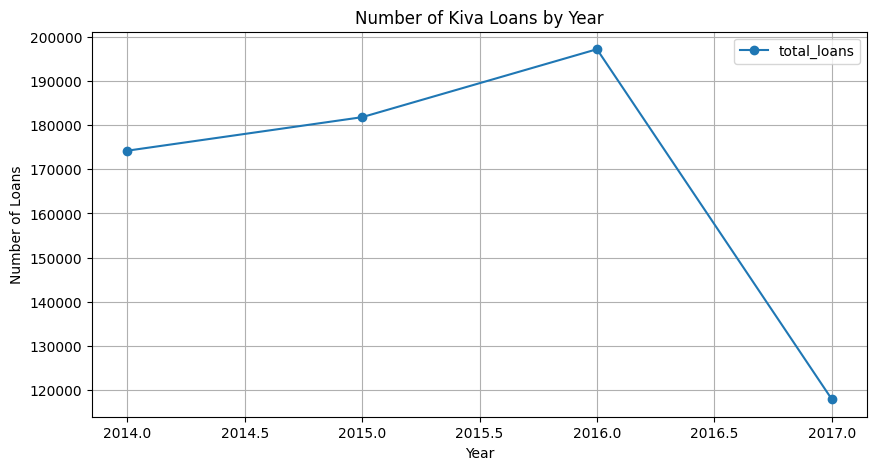

In [ ]:
yearly_loans.sort_index().plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Number of Kiva Loans by Year',
    xlabel='Year',
    ylabel='Number of Loans',
    grid=True
)

### Interpretation

The number of Kiva loans increased between 2014 and 2016, reaching a peak of 197,236 loans in 2016. However, the number dropped to 117,902 in 2017. This shows that lending activity grew during the first three years but declined considerably in the final year covered by the dataset.

## Question 6: How do loan repayment periods vary across different countries and currencies?

In [ ]:
df[['currency', 'term_in_months', 'loan_amount']].head(10)

,currency,term_in_months,loan_amount
0,PKR,12.0,300.0
1,PKR,11.0,575.0
2,INR,43.0,150.0
3,PKR,11.0,200.0
4,PKR,14.0,400.0
5,KES,4.0,250.0
6,INR,43.0,200.0
7,PKR,14.0,400.0
8,PKR,14.0,475.0
9,PKR,11.0,625.0


In [ ]:
df['currency'].nunique()
df['currency'].value_counts().head(15)

,count
currency,
PHP,160440
USD,105494
KES,75311
KHR,29498
PKR,26856
COP,21984
PEN,21401
UGX,20534
XOF,18610


In [ ]:
currency_analysis = df.groupby('currency').agg(
    total_loans=('id', 'count'),
    average_repayment=('term_in_months', 'mean'),
    median_repayment=('term_in_months', 'median')
)

currency_analysis = currency_analysis[
    currency_analysis['total_loans'] >= 1000
]

currency_analysis.sort_values(
    by='average_repayment',
    ascending=False
)

,total_loans,average_repayment,median_repayment
currency,,,
CRC,1561,32.419603,38.0
INR,11221,31.781125,43.0
AMD,5988,28.042418,26.0
ALL,1933,23.831868,26.0
IDR,6109,22.348011,14.0
GEL,1570,21.765605,21.0
EUR,1419,21.045102,22.0
JOD,4175,18.906587,18.0
MZN,3482,17.913268,18.0


In [ ]:
print("Five currencies with the longest repayment periods:")
display(currency_analysis.sort_values(
    by='average_repayment',
    ascending=False
).head(5))

print("Five currencies with the shortest repayment periods:")
display(currency_analysis.sort_values(
    by='average_repayment',
    ascending=True
).head(5))

Five currencies with the longest repayment periods:


,total_loans,average_repayment,median_repayment
currency,,,
CRC,1561,32.419603,38.0
INR,11221,31.781125,43.0
AMD,5988,28.042418,26.0
ALL,1933,23.831868,26.0
IDR,6109,22.348011,14.0


Five currencies with the shortest repayment periods:


,total_loans,average_repayment,median_repayment
currency,,,
TRY,1703,8.538462,8.0
XOF,18610,8.741591,8.0
TZS,5178,9.215141,8.0
LAK,1481,9.569210,10.0
PEN,21401,9.614224,8.0


In [ ]:
currency_country_analysis = df.groupby(
    ['currency', 'country']
).agg(
    total_loans=('id', 'count'),
    average_repayment=('term_in_months', 'mean'),
    median_repayment=('term_in_months', 'median')
)

currency_country_analysis = currency_country_analysis[
    currency_country_analysis['total_loans'] >= 1000
]

currency_country_analysis.sort_values(
    by='average_repayment',
    ascending=False
)

total_loans  average_repayment  \
currency country                                                                
CRC      Costa Rica                                   1561          32.419603   
INR      India                                       11221          31.781125   
USD      Armenia                                      2643          29.012107   
AMD      Armenia                                      5988          28.042418   
USD      United States                                6093          26.987855   
         Palestine                                    8155          26.716248   
         Cambodia                                     5338          25.353129   
ALL      Albania                                      1933          23.831868   
IDR      Indonesia                                    6109          22.348011   
USD      Bolivia                                      1481          22.264011   
GEL      Georgia                                      1570          21.765605   
EUR      Kosovo                                       1419          21.045102   
USD      Tajikistan                                   2027          20.059694   
JOD      Jordan                                       4167          18.895608   
USD      Nicaragua                                    4596          18.069191   
MZN      Mozambique                                   3482          17.913268   
COP      Colombia                                    21984          17.719387   
YER      Yemen                                        2313          17.668396   
VND      Vietnam                                     10843          17.623905   
BOB      Bolivia                                      7325          17.022253   
AZN      Azerbaijan                                   1944          16.615741   
NGN      Nigeria                                     10135          16.605821   
HNL      Honduras                                     6463          16.256692   
HTG      Haiti                                        3384          15.906619   
TJS      Tajikistan                                  17553          15.828462   
USD      El Salvador                                 39875          15.688677   
KGS      Kyrgyzstan                                   5424          15.366335   
XAF      Cameroon                                     2230          14.943946   
LBP      Lebanon                                      2077          14.801156   
USD      Timor-Leste                                  2690          14.748327   
         Lebanon                                      6715          14.696649   
EGP      Egypt                                        1639          14.001830   
WST      Samoa                                        7395          13.933469   
GTQ      Guatemala                                    7243          13.626122   
PKR      Pakistan                                    26856          13.510463   
NIO      Nicaragua                                    7185          12.506750   
MXN      Mexico                                       5689          12.360696   
KES      Kenya                                       75311          12.317988   
KHR      Cambodia                                    29498          12.076242   
USD      Ecuador                                     13521          12.000888   
UGX      Uganda                                      20534          11.577822   
MMK      Myanmar (Burma)                              1866          11.520900   
GHS      Ghana                                        4257          11.020437   
XOF      Senegal                                      3268          10.988372   
MWK      Malawi                                       1319          10.870356   
LRD      Liberia                                      3551          10.740918   
RWF      Rwanda                                       6711          10.710773   
PYG      Paraguay                                    11898          10.103967 

In [ ]:
print("Five longest average repayment periods:")
display(currency_country_analysis.sort_values(
    by='average_repayment',
    ascending=False
).head(5))

print("Five shortest average repayment periods:")
display(currency_country_analysis.sort_values(
    by='average_repayment',
    ascending=True
).head(5))

Five longest average repayment periods:


,,total_loans,average_repayment,median_repayment
currency,country,,,
CRC,Costa Rica,1561,32.419603,38.0
INR,India,11221,31.781125,43.0
USD,Armenia,2643,29.012107,26.0
AMD,Armenia,5988,28.042418,26.0
USD,United States,6093,26.987855,24.0


Five shortest average repayment periods:


,,total_loans,average_repayment,median_repayment
currency,country,,,
XOF,Burkina Faso,2460,7.413415,8.0
USD,The Democratic Republic of the Congo,3073,7.706801,7.0
XOF,Mali,6638,7.954052,8.0
TRY,Turkey,1703,8.538462,8.0
XOF,Togo,5749,8.786050,8.0


<Axes: title={'center': 'Countries with the Longest and Shortest Average Repayment Periods'}, xlabel='Average Repayment Period (Months)', ylabel='Country'>

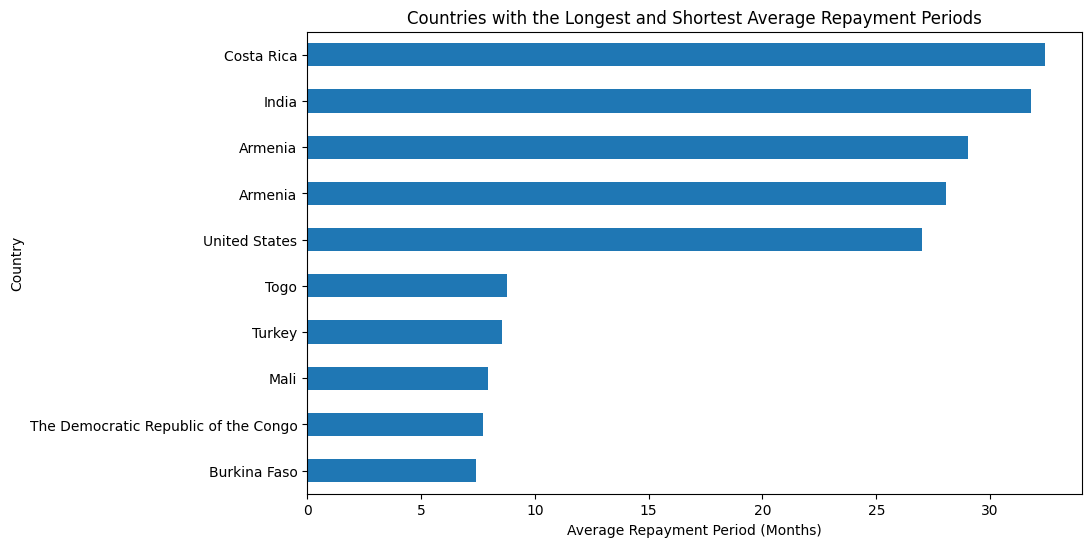

### Interpretation

Costa Rica (CRC) recorded the longest average repayment period at 32.42 months, followed by India (INR) at 31.78 months and Armenia (AMD) at 28.04 months. In contrast, Turkey (TRY) had the shortest average repayment period at 8.54 months, followed by countries using the West African CFA franc (XOF), including Senegal, Togo and Mali. The comparison suggests that repayment periods vary across countries and currencies.